Análise do relatório de doenças por procedência

In [1]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as pl #importa o pacote de plotagem
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 400
import seaborn as sns
import numpy as np
import plotly.express as px

In [58]:
df_dp = pd.read_csv('C:/Users/thami/OneDrive/Documentos/Unitoledo/Pesquisa e produtividade/dados/relatorio de doenças por procedencia.csv', 
                 sep=None,          # Let pandas detect the separator
                 engine='python',   # Use the python engine which is more flexible
                 encoding='utf-8',  # Specify encoding to handle special characters
                 on_bad_lines='warn')  # Use on_bad_lines instead of error_bad_lines
print(df_dp.head())

   MES_ANO UF_PROCEDENCIA  ESPECIE            DIAGNOSTICO  \
0  01/2003             PA  Bovinos                Bursite   
1  01/2004             RS   Suinos               Pleurite   
2  01/2005             SC     Aves             Septicemia   
3  01/2006             SP     Aves  Evisceracao Retardada   
4  01/2007             PE     Aves           Colibacilose   

   NUMERO_ANIMAIS_ACOMETIDOS  
0                          6  
1                         17  
2                        292  
3                         21  
4                         15  


In [64]:
#analisando o formato das colunas
df_dp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244948 entries, 0 to 244947
Data columns (total 5 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   MES_ANO                    244948 non-null  object 
 1   UF_PROCEDENCIA             244948 non-null  object 
 2   ESPECIE                    244948 non-null  object 
 3   DIAGNOSTICO                244948 non-null  object 
 4   NUMERO_ANIMAIS_ACOMETIDOS  244948 non-null  float64
dtypes: float64(1), object(4)
memory usage: 9.3+ MB


In [60]:
#analisando a estatística básica
pd.set_option('display.float_format', '{:.0f}'.format) #0f é para sem casa decimal
print(df_dp.describe())

       NUMERO_ANIMAIS_ACOMETIDOS
count                     244948
mean                       15438
std                       123208
min                            0
25%                            4
50%                           44
75%                          966
max                      5733671


In [61]:
#identificar colunas com not a number (NaN)
df_dp.isna().sum()

MES_ANO                      0
UF_PROCEDENCIA               0
ESPECIE                      0
DIAGNOSTICO                  0
NUMERO_ANIMAIS_ACOMETIDOS    0
dtype: int64

In [62]:
#identificar linhas que contenham algum not a number (NaN)
df_dp[df_dp.isna().any(axis=1)]

,MES_ANO,UF_PROCEDENCIA,ESPECIE,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS


In [63]:
#verifica a quantidade de informados 0
df_dp_zero = (df_dp == 0).sum()
print(df_dp_zero)

MES_ANO                        0
UF_PROCEDENCIA                 0
ESPECIE                        0
DIAGNOSTICO                    0
NUMERO_ANIMAIS_ACOMETIDOS    371
dtype: int64


In [65]:
#analisa a presença de duplicados
df_dp.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
244943    False
244944    False
244945    False
244946    False
244947    False
Length: 244948, dtype: bool

In [66]:
#analisa para encontrar linhas duplicadas
duplicate_dp = df_dp[df_dp.duplicated()]
print(duplicate_dp) #resultado sem linhas duplicadas

Empty DataFrame
Columns: [MES_ANO, UF_PROCEDENCIA, ESPECIE, DIAGNOSTICO, NUMERO_ANIMAIS_ACOMETIDOS]
Index: []


In [67]:
#convertendo a coluna NUMERO_ANIMAIS_ACOMETIDOS para inteiro
df_dp['NUMERO_ANIMAIS_ACOMETIDOS'] = df_dp['NUMERO_ANIMAIS_ACOMETIDOS'].astype(int)
print(df_dp.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244948 entries, 0 to 244947
Data columns (total 5 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   MES_ANO                    244948 non-null  object
 1   UF_PROCEDENCIA             244948 non-null  object
 2   ESPECIE                    244948 non-null  object
 3   DIAGNOSTICO                244948 non-null  object
 4   NUMERO_ANIMAIS_ACOMETIDOS  244948 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 9.3+ MB
None


In [68]:
df_dp.nunique()

MES_ANO                        309
UF_PROCEDENCIA                  27
ESPECIE                         46
DIAGNOSTICO                    705
NUMERO_ANIMAIS_ACOMETIDOS    33038
dtype: int64

In [69]:
print(df_dp.dtypes)

MES_ANO                      object
UF_PROCEDENCIA               object
ESPECIE                      object
DIAGNOSTICO                  object
NUMERO_ANIMAIS_ACOMETIDOS     int64
dtype: object


In [70]:
#alterando os valores da coluna DIAGNOSTICO para minúsculo e sem espaços em branco
df_dp.loc[:,'DIAGNOSTICO'] = df_dp['DIAGNOSTICO'].str.strip().str.lower()
print(df_dp)

        MES_ANO UF_PROCEDENCIA  ESPECIE  \
0       01/2003             PA  Bovinos   
1       01/2004             RS   Suinos   
2       01/2005             SC     Aves   
3       01/2006             SP     Aves   
4       01/2007             PE     Aves   
...         ...            ...      ...   
244943  12/2025             MA   Bovino   
244944  12/2025             MG  Galinha   
244945  12/2025             PR     Peru   
244946  12/2025             RO   Bovino   
244947  12/2025             SC   Frango   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0                                         bursite                          6  
1                                        pleurite                         17  
2                                      septicemia                        292  
3                           evisceracao retardada                         21  
4                                    colibacilose                         15  
...      

In [91]:
df_dp["MES_ANO"] = pd.to_datetime(df_dp["MES_ANO"], format="%m/%Y", errors='coerce')
df_dp["ANO"] = df_dp["MES_ANO"].dt.year
print(df_dp.head())

     MES_ANO UF_PROCEDENCIA  ESPECIE            DIAGNOSTICO  \
0 2003-01-01             PA  Bovinos                bursite   
1 2004-01-01             RS   Suinos               pleurite   
2 2005-01-01             SC     Aves             septicemia   
3 2006-01-01             SP     Aves  evisceracao retardada   
4 2007-01-01             PE     Aves           colibacilose   

   NUMERO_ANIMAIS_ACOMETIDOS   ANO  
0                          6  2003  
1                         17  2004  
2                        292  2005  
3                         21  2006  
4                         15  2007  


In [92]:
df_dp.head()

,MES_ANO,UF_PROCEDENCIA,ESPECIE,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,ANO
0,2003-01-01,PA,Bovinos,bursite,6,2003
1,2004-01-01,RS,Suinos,pleurite,17,2004
2,2005-01-01,SC,Aves,septicemia,292,2005
3,2006-01-01,SP,Aves,evisceracao retardada,21,2006
4,2007-01-01,PE,Aves,colibacilose,15,2007


In [93]:
df_dp['ESPECIE'].unique()

array(['Bovinos', 'Suinos', 'Aves', 'Ovinos', 'Frango', 'Ovino', 'Bovino',
       'Suíno', 'Equino', 'Galinha', 'Jacaré', 'Equideos', 'Avestruz',
       'Galo', 'Bubalino', 'Peru', 'Pato', 'Codorna', 'Caprinos',
       'Asinino', 'Bubalinos', 'Peixe', 'Muar', 'Ratitas', 'Coelho',
       'Leporideos', 'Camarão', 'Tilápia', 'Caprino', 'Outros anfíbios',
       'Capivara', "Galinha-d'angola", 'Tilápia do Nilo',
       'Uma ou mais espécies', 'Rã-touro',
       'Aves não destinadas à produção de carne ou ovos (ornamentais/silvestres)',
       'Rã', 'Tilápia, Tilápia-do-Nilo', 'Javali', 'Lagosta', 'Ganso',
       'Jacaré-do-papo-amarelo', 'Jacaré do pantanal', 'Ovelha', 'Ostra',
       'Lambari'], dtype=object)

In [94]:
# fica somente com a células que não tem zero no número de animais acometidos
df_dp_1 = df_dp[df_dp['NUMERO_ANIMAIS_ACOMETIDOS'] != 0]
print(df_dp_1)

          MES_ANO UF_PROCEDENCIA  ESPECIE  \
0      2003-01-01             PA  Bovinos   
1      2004-01-01             RS   Suinos   
2      2005-01-01             SC     Aves   
3      2006-01-01             SP     Aves   
4      2007-01-01             PE     Aves   
...           ...            ...      ...   
244943 2025-12-01             MA   Bovino   
244944 2025-12-01             MG  Galinha   
244945 2025-12-01             PR     Peru   
244946 2025-12-01             RO   Bovino   
244947 2025-12-01             SC   Frango   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  \
0                                         bursite                          6   
1                                        pleurite                         17   
2                                      septicemia                        292   
3                           evisceracao retardada                         21   
4                                    colibacilose          

In [97]:
variaveis = ["ANO","UF_PROCEDENCIA", "ESPECIE", "DIAGNOSTICO"]

for var in variaveis:
    resumo = (
        df_dp_1.groupby(var, as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
          .sum()
          .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
    )
    
    resumo["percentual"] = (
        resumo["NUMERO_ANIMAIS_ACOMETIDOS"] / resumo["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
    )
    
    print(f"\nResumo por {var}")
    display(resumo.head(20))


Resumo por ANO


,ANO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
24,2024,597799958,16
25,2025,590540066,16
23,2023,571608312,15
22,2022,561559207,15
21,2021,434828517,11
26,2026,122455024,3
19,2019,73968541,2
8,2008,70565627,2
10,2010,66603467,2
9,2009,64593806,2



Resumo por UF_PROCEDENCIA


,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
17,PR,1166601865,31
23,SC,591354769,16
10,MG,528947853,14
22,RS,384160445,10
25,SP,315141474,8
8,GO,306191177,8
12,MT,175958758,5
11,MS,115341737,3
7,ES,61063825,2
6,DF,25974760,1



Resumo por ESPECIE


,ESPECIE,NUMERO_ANIMAIS_ACOMETIDOS,percentual
16,Frango,2321035767,61
1,Aves,1083728367,29
17,Galinha,213592643,6
41,Suíno,83007818,2
4,Bovino,23070541,1
36,Peru,21986182,1
40,Suinos,20143814,1
5,Bovinos,8458332,0
35,Peixe,2146541,0
34,Pato,1519968,0



Resumo por DIAGNOSTICO


,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
142,contaminação gastrointestinal e biliar,886552406,23
278,lesão de pele,507439460,13
54,artrite (uma articulação),300473008,8
23,aerossaculite (aves),261166258,7
144,contusão,187702103,5
141,contaminacao,184109978,5
211,falha tecnológica,147370843,4
112,celulite (aves),133092224,4
53,artrite (mais de uma articulação),127571638,3
281,lesão traumática,120142576,3


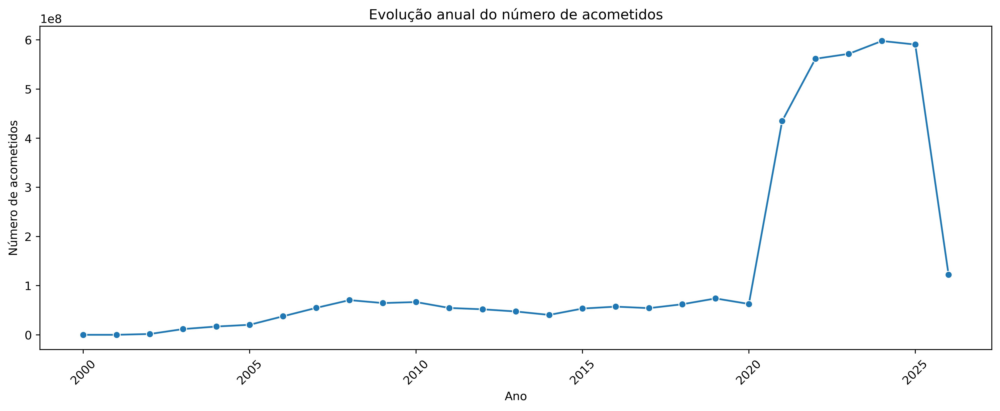

In [98]:
serie_mensal = (
    df_dp_1.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
)

pl.figure(figsize=(12, 5))
sns.lineplot(
    data=serie_mensal,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    marker="o"
)

pl.title("Evolução anual do número de acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(rotation=45)
pl.tight_layout()
pl.show()

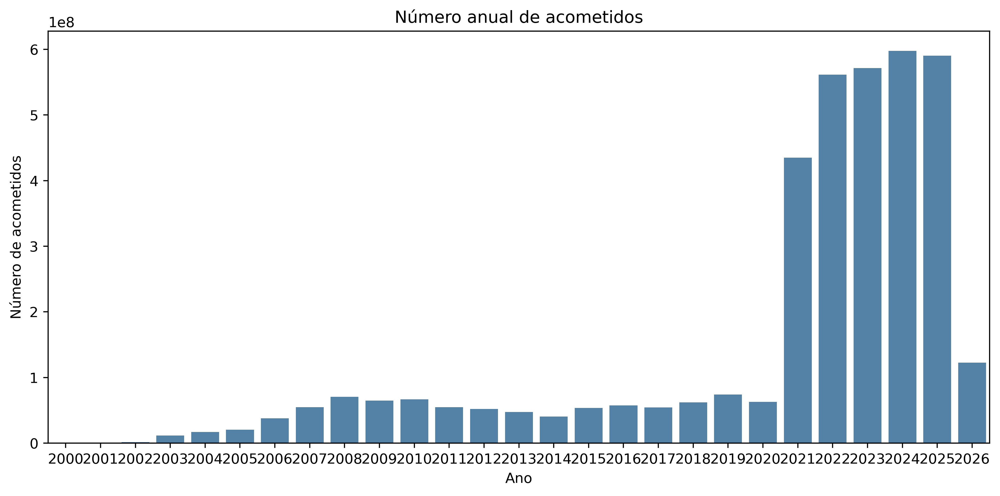

In [99]:
pl.figure(figsize=(10, 5))

sns.barplot(
    data = (
    df_dp_1.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
                        ),
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    color="steelblue"
)

pl.title("Número anual de acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.tight_layout()
pl.show()

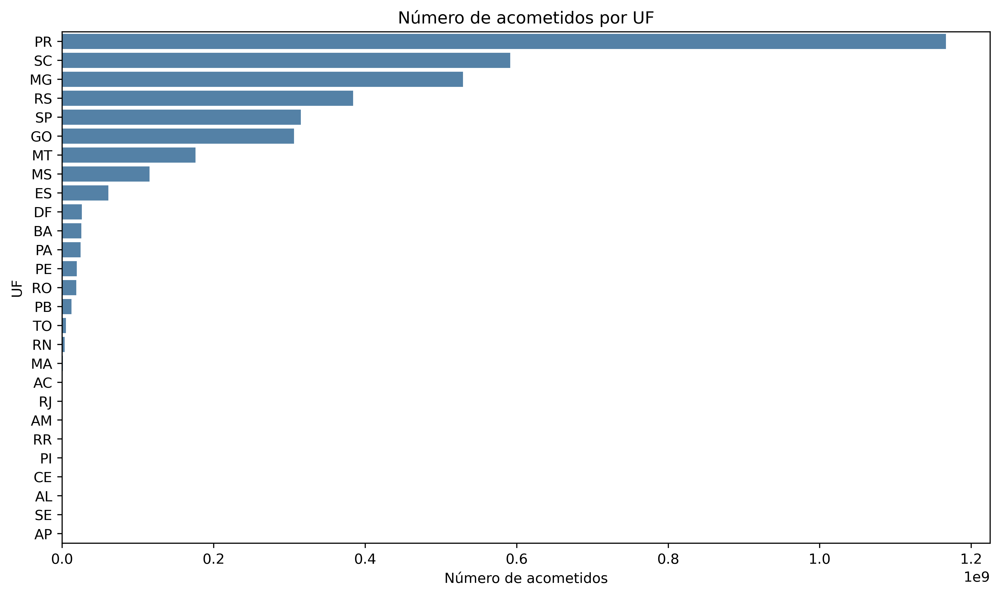

In [88]:
ranking_uf = (
    df_dp_1.groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

pl.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

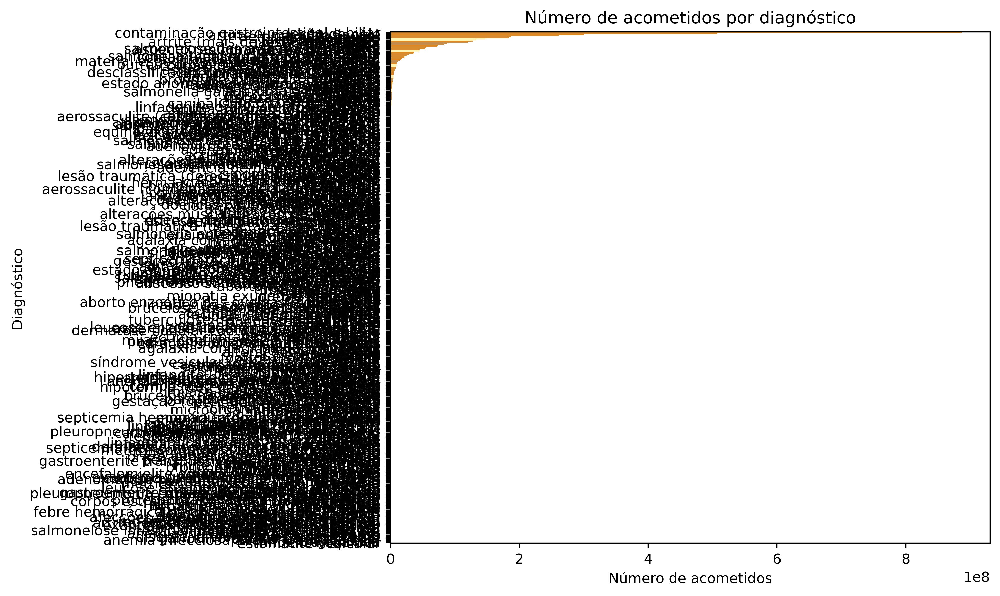

In [89]:
ranking_diagnostico = (
    df_dp_1.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

pl.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_diagnostico,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="DIAGNOSTICO",
    color="darkorange"
)

pl.title("Número de acometidos por diagnóstico")
pl.xlabel("Número de acometidos")
pl.ylabel("Diagnóstico")
pl.tight_layout()
pl.show()

In [90]:
tabela_uf_diagnostico = pd.pivot_table(
    df_dp_1,
    values="NUMERO_ANIMAIS_ACOMETIDOS",
    index="UF_PROCEDENCIA",
    columns="DIAGNOSTICO",
    aggfunc="sum",
    fill_value=0
)

tabela_uf_diagnostico

DIAGNOSTICO,aborto enzoótico das ovelhas (confirmado),aborto recente (fêmea),abscesso,abscesso (mamífero),abscesso (mamíferos),abscesso subcutâneo (lagomorfos),acidez,acidez acima de 20 graus dornic,acrobustite,actinobacilose,...,umidade acima do padrão,uronefrose,urticaria,vaginite glanulosa,variola,varredura,varíola bovina (já notificado),verminose,visceras hemorragicas,útero com feto(s)
UF_PROCEDENCIA,,,,,,,,,,,,,,,,,,,,,
AC,0,4,1830,90,648,0,0,0,113,0,...,0,5,0,0,12,0,0,3,0,0
AL,0,0,0,0,178,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AM,0,0,1054,0,269,0,0,0,0,0,...,0,497,0,0,0,0,0,0,0,0
AP,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BA,0,11,460,5,1176,3,0,0,0,6,...,0,10,0,0,0,0,0,0,0,1
CE,0,0,0,0,79,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
DF,0,0,571584,0,448,0,0,0,0,0,...,0,0,0,0,0,0,12,0,0,0
ES,0,0,462971,0,997,108,0,0,0,0,...,0,0,0,618,0,0,0,10390,1582933,0
GO,46,13,53553,247,24051,56,0,0,29,0,...,0,35,0,0,0,0,0,3,0,14


In [101]:
ranking_uf = (
    df_dp_1.groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_uf

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS
17,PR,1166601865
23,SC,591354769
10,MG,528947853
22,RS,384160445
25,SP,315141474
8,GO,306191177
12,MT,175958758
11,MS,115341737
7,ES,61063825
6,DF,25974760


<Figure size 4000x2400 with 0 Axes>

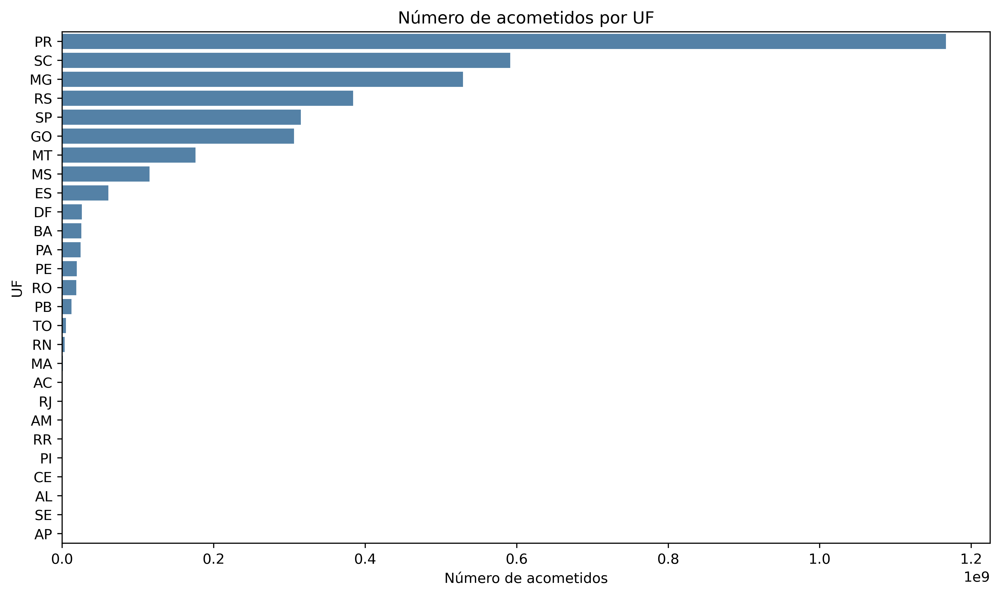

In [103]:
pl.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [104]:
ranking_uf["percentual"] = (
    ranking_uf["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_uf["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_uf

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
17,PR,1166601865,31
23,SC,591354769,16
10,MG,528947853,14
22,RS,384160445,10
25,SP,315141474,8
8,GO,306191177,8
12,MT,175958758,5
11,MS,115341737,3
7,ES,61063825,2
6,DF,25974760,1


In [105]:
ranking_diagnostico = (
    df_dp_1.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
142,contaminação gastrointestinal e biliar,886552406
278,lesão de pele,507439460
54,artrite (uma articulação),300473008
23,aerossaculite (aves),261166258
144,contusão,187702103
...,...,...
356,paralisia post partum,1
42,anemia infecciosa aves (notificação sif),1
46,angiectasia,1
268,influenza equidea,1


In [107]:
ranking_diagnostico["percentual"] = (
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
142,contaminação gastrointestinal e biliar,886552406,23
278,lesão de pele,507439460,13
54,artrite (uma articulação),300473008,8
23,aerossaculite (aves),261166258,7
144,contusão,187702103,5
...,...,...,...
356,paralisia post partum,1,0
42,anemia infecciosa aves (notificação sif),1,0
46,angiectasia,1,0
268,influenza equidea,1,0


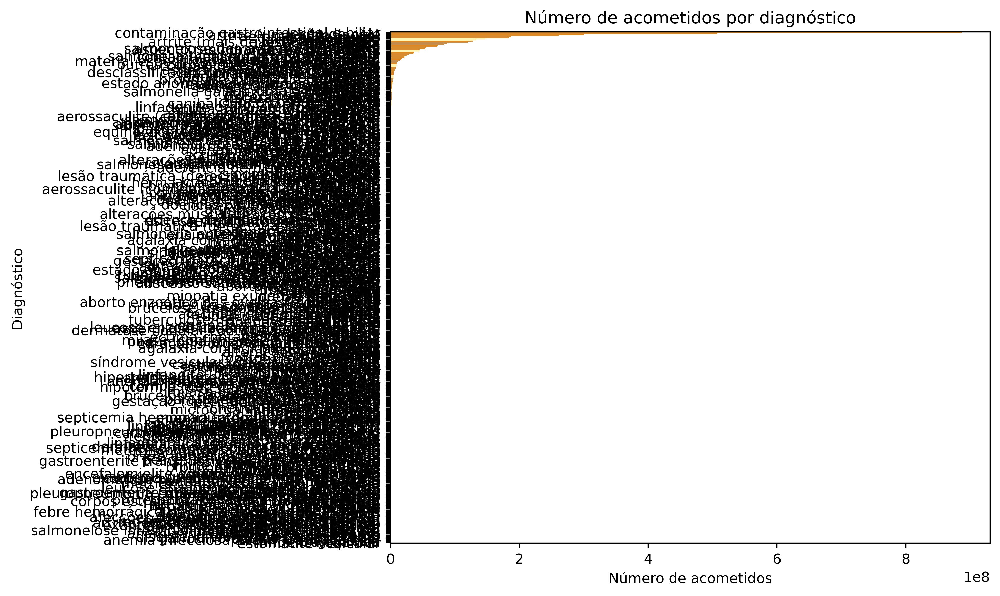

In [108]:
pl.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_diagnostico,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="DIAGNOSTICO",
    color="darkorange"
)

pl.title("Número de acometidos por diagnóstico")
pl.xlabel("Número de acometidos")
pl.ylabel("Diagnóstico")
pl.tight_layout()
pl.show()

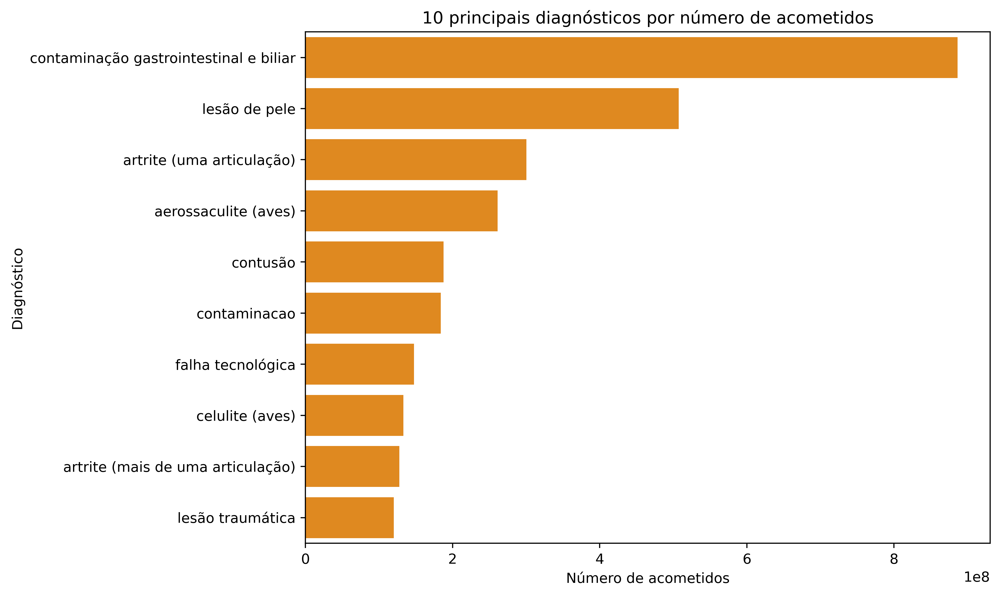

In [109]:
top10_diagnostico = ranking_diagnostico.head(10)

pl.figure(figsize=(10, 6))

sns.barplot(
    data=top10_diagnostico,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="DIAGNOSTICO",
    color="darkorange"
)

pl.title("10 principais diagnósticos por número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Diagnóstico")
pl.tight_layout()
pl.show()

In [112]:
diagnostico_ano = (
    df_dp_1.groupby(["ANO", "DIAGNOSTICO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(["ANO", "NUMERO_ANIMAIS_ACOMETIDOS"], ascending=[True, False])
)

diagnostico_ano

,ANO,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
6,2000,escaldagem excessiva,1398
11,2000,pleurite,1056
8,2000,lesão traumática,491
3,2000,contaminacao,400
10,2000,odor estranho,144
...,...,...,...
4372,2026,footrot (já notificado),1
4373,2026,footrot (notificação sif),1
4389,2026,leucose enzoótica bovina (já notificado),1
4419,2026,septicemia hemorrágica bovina (notificação sif),1


In [114]:
pl.figure(figsize=(12, 6))

sns.lineplot(
    data=diagnostico_ano,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    hue="DIAGNOSTICO",
    marker="o"
)

pl.title("Evolução anual dos diagnósticos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(sorted(diagnostico_ano["ANO"].unique()))
pl.legend(title="Diagnóstico", bbox_to_anchor=(1.05, 1), loc="upper left")
pl.tight_layout()
pl.show()

C:\Users\thami\AppData\Local\Temp\ipykernel_28432\4158796116.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  pl.tight_layout()


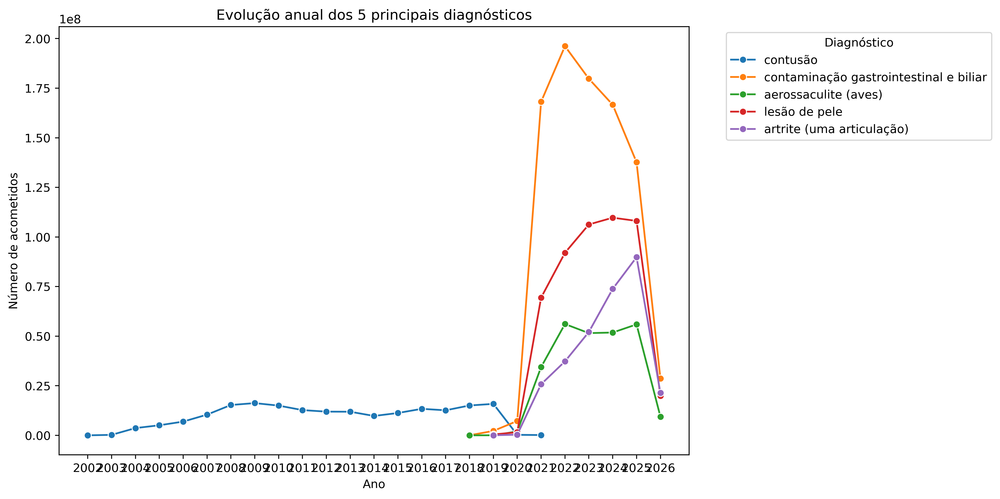

In [115]:
top5_diag = (
    df_dp_1.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
      .index
)

diagnostico_ano_top5 = diagnostico_ano[
    diagnostico_ano["DIAGNOSTICO"].isin(top5_diag)
]

pl.figure(figsize=(12, 6))

sns.lineplot(
    data=diagnostico_ano_top5,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    hue="DIAGNOSTICO",
    marker="o"
)

pl.title("Evolução anual dos 5 principais diagnósticos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(sorted(diagnostico_ano_top5["ANO"].unique()))
pl.legend(title="Diagnóstico", bbox_to_anchor=(1.05, 1), loc="upper left")
pl.tight_layout()
pl.show()

In [78]:
#filtrar pelas espécies referente a pesquisa - bovinos e suínos
df_dp_2 = df_dp_1[df_dp_1['ESPECIE'].isin(['Bovinos', 'Suinos','Bovino','Suíno'])]
print(df_dp_2)

        MES_ANO UF_PROCEDENCIA  ESPECIE  \
0       01/2003             PA  Bovinos   
1       01/2004             RS   Suinos   
7       01/2010             ES  Bovinos   
10      01/2013             MS  Bovinos   
13      01/2014             SP  Bovinos   
...         ...            ...      ...   
244936  12/2022             MG    Suíno   
244939  12/2023             GO    Suíno   
244940  12/2023             MT   Bovino   
244943  12/2025             MA   Bovino   
244946  12/2025             RO   Bovino   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0                                         bursite                          6  
1                                        pleurite                         17  
7                        cisticercose calcificada                         36  
10                                       contusão                          7  
13                                       contusão                        738  
...      

In [79]:
#corrigindo os valores da coluna ESPECIE para ficar somente no singular
df_dp_2['ESPECIE'] = df_dp_2['ESPECIE'].replace({'Bovinos': 'Bovino', 'Suinos': 'Suíno'})
print(df_dp_2)

        MES_ANO UF_PROCEDENCIA ESPECIE  \
0       01/2003             PA  Bovino   
1       01/2004             RS   Suíno   
7       01/2010             ES  Bovino   
10      01/2013             MS  Bovino   
13      01/2014             SP  Bovino   
...         ...            ...     ...   
244936  12/2022             MG   Suíno   
244939  12/2023             GO   Suíno   
244940  12/2023             MT  Bovino   
244943  12/2025             MA  Bovino   
244946  12/2025             RO  Bovino   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0                                         bursite                          6  
1                                        pleurite                         17  
7                        cisticercose calcificada                         36  
10                                       contusão                          7  
13                                       contusão                        738  
...                  

C:\Users\thami\AppData\Local\Temp\ipykernel_28432\927632661.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_dp_2['ESPECIE'] = df_dp_2['ESPECIE'].replace({'Bovinos': 'Bovino', 'Suinos': 'Suíno'})


In [80]:
#separa os dados por espécie
df_bovino = df_dp_1[df_dp_1['ESPECIE'] == 'Bovino']
print(df_bovino)

        MES_ANO UF_PROCEDENCIA ESPECIE  \
26      01/2023             MA  Bovino   
28      01/2023             RS  Bovino   
29      01/2023             TO  Bovino   
30      01/2024             AC  Bovino   
32      01/2024             PA  Bovino   
...         ...            ...     ...   
244932  12/2021             ES  Bovino   
244933  12/2021             RO  Bovino   
244940  12/2023             MT  Bovino   
244943  12/2025             MA  Bovino   
244946  12/2025             RO  Bovino   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
26                       parasitose não zoonótica                         21  
28                                 fígado amarelo                         21  
29                             alteração restrita                       6660  
30                       parasitose não zoonótica                         23  
32      equinococose/hidatidose (notificaçao sif)                          3  
...                  

In [81]:
df_bovino.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33823 entries, 26 to 244946
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   MES_ANO                    33823 non-null  object
 1   UF_PROCEDENCIA             33823 non-null  object
 2   ESPECIE                    33823 non-null  object
 3   DIAGNOSTICO                33823 non-null  object
 4   NUMERO_ANIMAIS_ACOMETIDOS  33823 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.5+ MB


In [82]:
df_bovino.describe()

,NUMERO_ANIMAIS_ACOMETIDOS
count,33823
mean,682
std,3856
min,1
25%,1
50%,6
75%,57
max,88827


In [57]:
#CONFERINDO O VALOR MÁXIMO DO DESCRIBE
df_bovino_max = df_bovino[['UF_PROCEDENCIA','DIAGNOSTICO','NUMERO_ANIMAIS_ACOMETIDOS']].max()
print(df_bovino_max)

UF_PROCEDENCIA                              TO
DIAGNOSTICO                  útero com feto(s)
NUMERO_ANIMAIS_ACOMETIDOS                88827
dtype: object


In [58]:
#CONFERINDO O VALOR MÁXIMO DO DESCRIBE
df_bovino_min = df_bovino[['UF_PROCEDENCIA','DIAGNOSTICO','NUMERO_ANIMAIS_ACOMETIDOS']].min()
print(df_bovino_min)

UF_PROCEDENCIA                                                      AC
DIAGNOSTICO                  aborto enzoótico das ovelhas (confirmado)
NUMERO_ANIMAIS_ACOMETIDOS                                            1
dtype: object


In [59]:
#verifica o valor de abate de bovinos por estado
abate_bovino = df_bovino.groupby('UF_PROCEDENCIA')['NUMERO_ANIMAIS_ACOMETIDOS'].sum().reset_index()
print(abate_bovino)

   UF_PROCEDENCIA  NUMERO_ANIMAIS_ACOMETIDOS
0              AC                     445961
1              AL                      13670
2              AM                     259580
3              AP                        814
4              BA                     789119
5              CE                       8075
6              DF                       6824
7              ES                     112578
8              GO                    3238055
9              MA                     471057
10             MG                    1572479
11             MS                    2145840
12             MT                    5730498
13             PA                    1407032
14             PB                      11139
15             PE                      48911
16             PI                      35574
17             PR                    1130304
18             RJ                      32113
19             RN                       3283
20             RO                    1130502
21        

In [84]:
df_bovino_AC = df_bovino[df_bovino['UF_PROCEDENCIA'] == 'AC']
print(df_bovino_AC)

        MES_ANO UF_PROCEDENCIA ESPECIE  \
30      01/2024             AC  Bovino   
173     04/2024             AC  Bovino   
191     05/2012             AC  Bovino   
193     05/2013             AC  Bovino   
208     05/2021             AC  Bovino   
...         ...            ...     ...   
244294  07/2024             AC  Bovino   
244566  02/2025             AC  Bovino   
244606  03/2025             AC  Bovino   
244648  04/2025             AC  Bovino   
244791  08/2021             AC  Bovino   

                                          DIAGNOSTICO  \
30                           parasitose não zoonótica   
173     material especificado de risco (inutilização)   
191                          cisticercose calcificada   
193                                         ictericia   
208                                           magreza   
...                                               ...   
244294    lesão traumática (detectada no ante mortem)   
244566    lesão traumática (detectada n

In [85]:
df_bovino_AC.info()


<class 'pandas.core.frame.DataFrame'>
Index: 2448 entries, 30 to 244791
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   MES_ANO                    2448 non-null   object
 1   UF_PROCEDENCIA             2448 non-null   object
 2   ESPECIE                    2448 non-null   object
 3   DIAGNOSTICO                2448 non-null   object
 4   NUMERO_ANIMAIS_ACOMETIDOS  2448 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 114.8+ KB


In [79]:
df_bovino_AC.describe()

,NUMERO_ANIMAIS_ACOMETIDOS
count,2448
mean,182
std,883
min,1
25%,1
50%,3
75%,20
max,8405


É possível cruzar o número de animais acometidos pelo número de abate ao longo do tempo

In [87]:
#verificar o total de animais acometidos pelo período em AC
df_bovino_AC.groupby("MES_ANO")["NUMERO_ANIMAIS_ACOMETIDOS"].sum()

MES_ANO
01/2010     304
01/2011     231
01/2012     153
01/2013     192
01/2014     164
           ... 
12/2021    9932
12/2022    7413
12/2023    9759
12/2024    9173
12/2025    2513
Name: NUMERO_ANIMAIS_ACOMETIDOS, Length: 202, dtype: int64

In [88]:
#verificar o total de animais acometidos pelo diagnóstico em AC
df_bovino_AC.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"].sum()

DIAGNOSTICO
aborto recente (fêmea)              4
abscesso                         1830
abscesso (mamífero)                90
abscesso (mamíferos)              535
acrobustite                         2
                                 ... 
tuberculose (já notificado)         1
tuberculose (notificação sif)      11
uronefrose                          5
variola                            12
verminose                           3
Name: NUMERO_ANIMAIS_ACOMETIDOS, Length: 118, dtype: int64

In [86]:
sorted_bovino_AC = df_bovino_AC.sort_values(by='NUMERO_ANIMAIS_ACOMETIDOS', ascending=False)
print(sorted_bovino_AC)

        MES_ANO UF_PROCEDENCIA ESPECIE  \
120996  02/2024             AC  Bovino   
104493  01/2024             AC  Bovino   
222125  12/2023             AC  Bovino   
187347  07/2023             AC  Bovino   
173     04/2024             AC  Bovino   
...         ...            ...     ...   
32867   04/2025             AC  Bovino   
136350  01/2026             AC  Bovino   
136323  01/2011             AC  Bovino   
136298  12/2021             AC  Bovino   
119552  02/2019             AC  Bovino   

                                          DIAGNOSTICO  \
120996  material especificado de risco (inutilização)   
104493  material especificado de risco (inutilização)   
222125  material especificado de risco (inutilização)   
187347  material especificado de risco (inutilização)   
173     material especificado de risco (inutilização)   
...                                               ...   
32867                      aderência de pleura (seca)   
136350                     aderência de

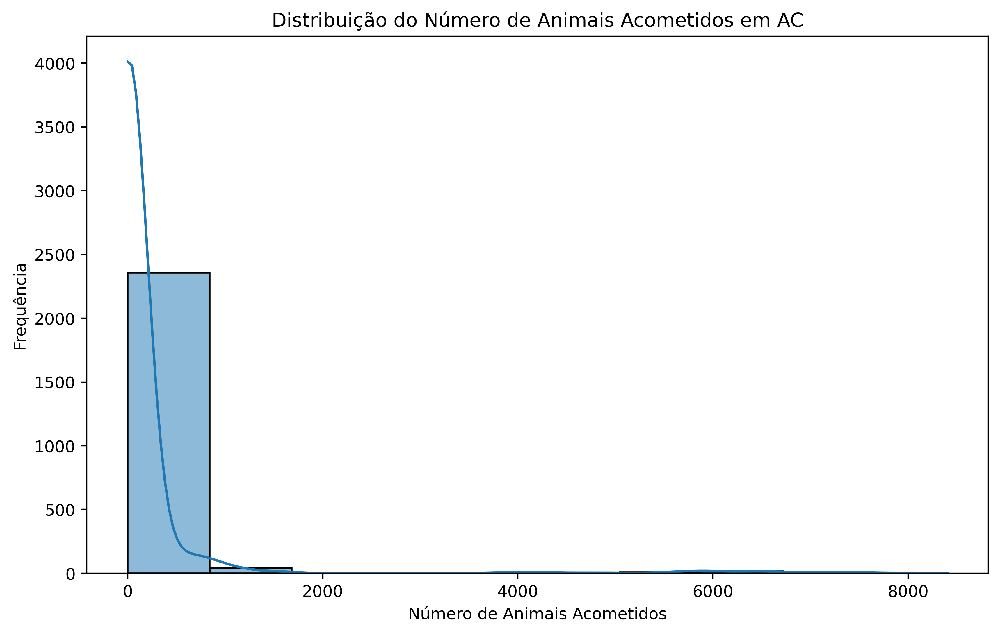

In [80]:
pl.figure(figsize=(10, 6))
sns.histplot(df_bovino_AC['NUMERO_ANIMAIS_ACOMETIDOS'], bins=10, kde=True)
pl.title('Distribuição do Número de Animais Acometidos em AC')
pl.xlabel('Número de Animais Acometidos')
pl.ylabel('Frequência')
pl.show()

In [81]:
df_suino = df_dp_1[df_dp_1['ESPECIE'] == 'Suíno']
print(df_suino)

        MES_ANO UF_PROCEDENCIA ESPECIE                            DIAGNOSTICO  \
1       01/2004             RS   Suíno                               pleurite   
21      01/2019             SC   Suíno               teleangiectasia maculosa   
27      01/2023             PR   Suíno       aspecto repugnante (post mortem)   
31      01/2024             MS   Suíno                     lesão inflamatória   
33      01/2024             PR   Suíno       aspecto repugnante (post mortem)   
...         ...            ...     ...                                    ...   
244926  12/2015             MG   Suíno                 impurezas superficiais   
244934  12/2021             SP   Suíno      erisipela suína (notificação sif)   
244935  12/2021             SP   Suíno                         esplenomegalia   
244936  12/2022             MG   Suíno  linfadenite caseosa (notificação sif)   
244939  12/2023             GO   Suíno                 prolapso (ante mortem)   

        NUMERO_ANIMAIS_ACOM

In [82]:
df_suino.describe()

,NUMERO_ANIMAIS_ACOMETIDOS
count,53019
mean,1946
std,12920
min,1
25%,5
50%,36
75%,359
max,327643


In [83]:
#verifica o valor de abate de suínos por estado
abate_suino = df_suino.groupby('UF_PROCEDENCIA')['NUMERO_ANIMAIS_ACOMETIDOS'].sum().reset_index()
print(abate_suino)

   UF_PROCEDENCIA  NUMERO_ANIMAIS_ACOMETIDOS
0              AC                     116428
1              AL                        212
2              AM                       6270
3              BA                       6225
4              CE                       3243
5              DF                     105868
6              ES                       1070
7              GO                    6316705
8              MA                       6597
9              MG                    8300314
10             MS                    5543150
11             MT                    4599881
12             PA                       2275
13             PB                        850
14             PE                      12914
15             PI                        425
16             PR                   22283305
17             RJ                      11889
18             RN                        206
19             RO                         72
20             RR                      14079
21        